# Веб-сервис и REST API из Python

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SergeyShk/Speech-to-Text-Russian/blob/master/notebooks/05_web_service.ipynb)

`stt-ru serve` запускает веб-интерфейс и REST API: модель загружается один раз, файлы распознаются в очереди. Ноутбук запускает сервис в фоне и работает с ним как программа: загрузка файла, ожидание результата, результат в разных форматах, форма волны, токен доступа, ошибки, удаление задачи и клиент для пакета файлов.

## Установка

В Colab ячейка ставит stt-ru и `pandas`, `matplotlib`, `httpx`; в окружении, где stt-ru с дополнением `service` уже есть, ничего не делает.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("uvicorn") is None:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "stt-ru[service]",
            "pandas",
            "matplotlib",
            "httpx",
        ],
        check=True,
    )

In [2]:
import urllib.request
from pathlib import Path

DATA = Path("data")
DATA.mkdir(exist_ok=True)
CALL = DATA / "call.wav"
if not CALL.exists():
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/SergeyShk/Speech-to-Text-Russian/master/tests/data/call.wav",
        CALL,
    )

## Запуск сервиса

Сервис запускается отдельным процессом на свободном порту с токеном доступа из переменной `STT_RU_TOKEN`; ячейка ждет, пока он загрузит модель и ответит на `/healthz`. На своем компьютере то же самое - `STT_RU_TOKEN=my-secret-token stt-ru serve`, после чего веб-интерфейс открывается в браузере.

In [3]:
import os
import socket
import subprocess
import sys
import time

import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf

pd.set_option("display.max_colwidth", None)

with socket.socket() as probe:
    probe.bind(("127.0.0.1", 0))
    PORT = probe.getsockname()[1]
TOKEN = "my-secret-token"
server = subprocess.Popen(
    [sys.executable, "-m", "stt_ru", "serve", "--port", str(PORT), "-q"],
    env={**os.environ, "STT_RU_TOKEN": TOKEN},
)
API = f"http://127.0.0.1:{PORT}"
client = httpx.Client(base_url=API, headers={"Authorization": f"Bearer {TOKEN}"}, timeout=60)
for _ in range(300):
    if server.poll() is not None:
        raise RuntimeError(f"stt-ru serve завершился с кодом {server.returncode}")
    try:
        if client.get("/healthz").status_code == 200:
            break
    except httpx.TransportError:
        time.sleep(1)
else:
    raise TimeoutError("stt-ru serve не ответил за 300 с")
client.get("/v1/info").json()

{'version': '0.3.0.dev9',
 'model': 'gigaam-v3-e2e-rnnt',
 'auth': True,
 'authorized': True,
 'max_size': 524288000,
 'max_duration': 10800.0,
 'keep': 86400.0,
 'formats': ['txt', 'json', 'jsonl', 'srt', 'vtt', 'ass', 'csv']}

## Распознавание файла

`POST /v1/transcriptions` ставит файл в очередь и сразу отвечает задачей; `GET /v1/jobs/{id}` показывает ее состояние: `queued`, `running`, `done` или `failed`.

In [4]:
with CALL.open("rb") as file:
    job = client.post("/v1/transcriptions", files={"file": ("call.wav", file, "audio/wav")}).json()
print("Задача:", job["id"], job["status"])
while job["status"] in ("queued", "running"):
    time.sleep(0.5)
    job = client.get(f"/v1/jobs/{job['id']}").json()
{key: job[key] for key in ("status", "filename", "duration", "channels", "segments", "expires")}

Задача: VDEBEnlVd_MLP6cZarANiw queued


{'status': 'done',
 'filename': 'call.wav',
 'duration': 15.751,
 'channels': 2,
 'segments': 5,
 'expires': '2026-10-12T14:27:54.132561Z'}

## Результат

`GET /v1/jobs/{id}/result` отдает результат в любом формате, по умолчанию JSON; имя файла - в заголовке `Content-Disposition`.

In [5]:
result = client.get(f"/v1/jobs/{job['id']}/result").json()
pd.DataFrame(result["segments"])[["start", "end", "speaker", "text"]]

,start,end,speaker,text
0,0.994,9.054,Канал 1,"Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии."
1,3.490,3.934,Канал 0,Угу
2,7.682,8.222,Канал 0,Угу
3,9.634,12.638,Канал 1,"Я в свою очередь с вами прощаюсь. Всего доброго, до свидания."
4,12.994,13.662,Канал 0,До свидания.


In [6]:
response = client.get(f"/v1/jobs/{job['id']}/result", params={"format": "srt"})
print(response.headers["content-disposition"])
print(response.text[:250])

attachment; filename="call.srt"; filename*=UTF-8''call.srt
1
00:00:00,994 --> 00:00:09,054
Канал 1: Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии.

2
00:00:03,490 --> 00:00:03,934
Канал 0: Угу

3


## Форма волны и запись

`/waveform` отдает пики амплитуды по каналам, `/audio` - загруженный файл с поддержкой перемотки (`Range`): так их использует веб-интерфейс.

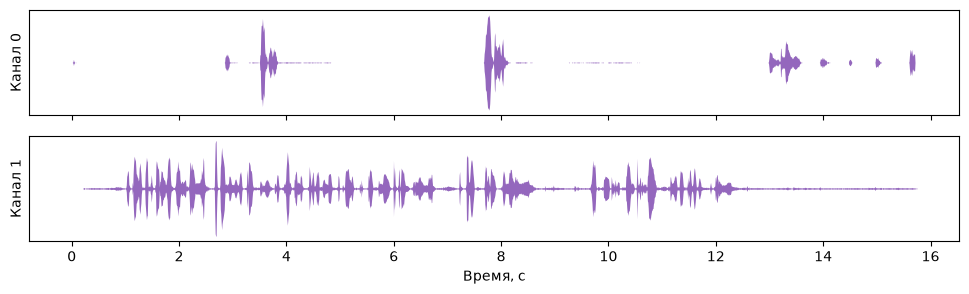

206 bytes 0-1023/504076 audio/x-wav


In [7]:
waveform = client.get(f"/v1/jobs/{job['id']}/waveform").json()
peaks = np.array(waveform["peaks"])
seconds = np.linspace(0, waveform["duration"], peaks.shape[1])
fig, axes = plt.subplots(len(peaks), 1, figsize=(12, 3), sharex=True)
for channel, ax in enumerate(axes):
    ax.fill_between(seconds, -peaks[channel], peaks[channel], color="tab:purple", linewidth=0)
    ax.set_ylabel(f"Канал {channel}")
    ax.set_yticks([])
axes[-1].set_xlabel("Время, с")
plt.show()

part = client.get(f"/v1/jobs/{job['id']}/audio", headers={"Range": "bytes=0-1023"})
print(part.status_code, part.headers["content-range"], part.headers["content-type"])

## Ошибки

Ошибки - JSON с полем `detail`: без токена - 401, неизвестный формат - 400, удаленная задача - 404.

In [8]:
print(httpx.get(f"{API}/v1/jobs/{job['id']}").json())
print(client.get(f"/v1/jobs/{job['id']}/result", params={"format": "docx"}).json())
print(client.delete(f"/v1/jobs/{job['id']}").status_code)
print(client.get(f"/v1/jobs/{job['id']}").json())

{'detail': 'Нужен токен доступа'}
{'detail': 'Неизвестный формат docx: допустимы txt, json, jsonl, srt, vtt, ass, csv'}
204
{'detail': 'Задачи нет: она удалена или срок хранения вышел'}


## Пакет файлов

Клиент ставит в очередь все файлы сразу, а результаты забирает по мере готовности. Сервис распознает их по очереди (`-j` задает, сколько одновременно), задачи и файлы хранятся 24 часа после окончания (`--keep`). В очереди не больше 100 задач (`--max-queue`): на следующий файл сервис отвечает 503, и клиент ждет, пока очередь освободится.

In [9]:
def submit(path):
    while True:
        with path.open("rb") as file:
            response = client.post("/v1/transcriptions", files={"file": (path.name, file)})
        if response.status_code != 503:
            response.raise_for_status()
            return response.json()["id"]
        time.sleep(5)


def transcribe_files(paths, fmt="txt"):
    jobs = {path.name: submit(path) for path in paths}
    results = {}
    while jobs:
        for name, job_id in list(jobs.items()):
            state = client.get(f"/v1/jobs/{job_id}").json()
            if state["status"] == "done":
                results[name] = client.get(
                    f"/v1/jobs/{job_id}/result", params={"format": fmt}
                ).text
            elif state["status"] == "failed":
                results[name] = f"ошибка: {state['error']}"
            else:
                continue
            client.delete(f"/v1/jobs/{job_id}")
            del jobs[name]
        time.sleep(0.5)
    return results


samples, rate = sf.read(CALL)
operator = DATA / "operator.wav"
sf.write(operator, samples[:, 1], rate)
for name, text in transcribe_files([CALL, operator]).items():
    print(f"== {name}\n{text}")

== call.wav
Канал 1: Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии.
Канал 0: Угу
Канал 0: Угу
Канал 1: Я в свою очередь с вами прощаюсь. Всего доброго, до свидания.
Канал 0: До свидания.

== operator.wav
Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии.
Я в свою очередь с вами прощаюсь. Всего доброго, до свидания.



## Остановка

In [10]:
client.close()
server.terminate()
server.wait(timeout=30)
print("Сервис остановлен")

Сервис остановлен


## Docker

Тот же сервис в Docker - модель уже в образе:

``` bash
docker run -d -p 8000:8000 -e STT_RU_TOKEN=my-secret-token ghcr.io/sergeyshk/stt-ru
```

Параметры сервиса, пределы размера и длительности, хранение файлов и все запросы REST API описаны на странице [Веб-сервис](https://sergeyshk.github.io/Speech-to-Text-Russian/service/) документации.